In [ ]:

import sys
sys.path.insert(0,'C:/Users/mailt/GaPP3-main.zip/GaPP3-main/') # please set your location where you put GaPP3 directory
sys.path.insert(0,'C:/Users/mailt/GaPP3-main.zip/GaPP3-main/gapp/')
sys.path.insert(0,'C:/Users/mailt/GaPP3-main.zip/GaPP3-main/gapp/covfunctions/')
#print(sys.path)

In [ ]:
import covfunctions
from gapp import gp,dgp
from gapp import covariance
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt


In [ ]:
import pandas as pd

data = pd.read_csv("File path of the data saved in your own computer.csv")

print(data.head())
print(data.columns)

   Unnamed: 0       z  H_value    H_error
0           0  0.0700    69.00  19.600000
1           1  0.0900    69.00  12.000000
2           2  0.1200    68.60  26.200000
3           3  0.1700    83.00   8.000000
4           4  0.1791    74.91   3.806926
Index(['Unnamed: 0', 'z', 'H_value', 'H_error'], dtype='str')


In [ ]:
print(data.head())
print(data.columns)

   Unnamed: 0       z  H_value    H_error
0           0  0.0700    69.00  19.600000
1           1  0.0900    69.00  12.000000
2           2  0.1200    68.60  26.200000
3           3  0.1700    83.00   8.000000
4           4  0.1791    74.91   3.806926
Index(['Unnamed: 0', 'z', 'H_value', 'H_error'], dtype='str')


In [ ]:
H = data["H_value"].to_numpy()
Herr = data["H_error"].to_numpy()
z = data["z"].to_numpy()

print(H.shape, Herr.shape, z.shape)

(32,) (32,) (32,)


<Figure size 640x480 with 0 Axes>

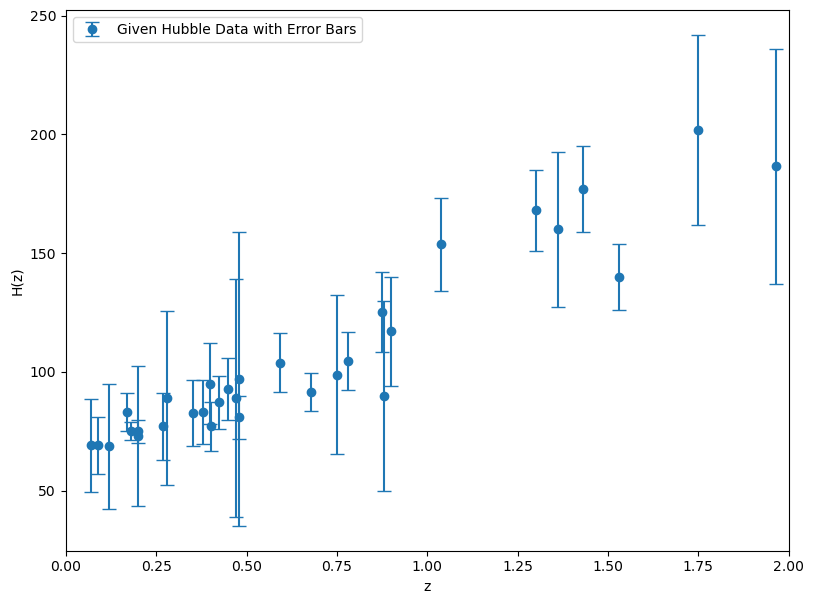

In [ ]:
plt.clf()
plt.figure(figsize=(8, 6))
plt.xlim(0, 2)
plt.tight_layout()
plt.xlabel('z')
plt.ylabel("H(z)")
plt.errorbar(z, H, yerr=Herr, fmt='o', capsize=5, label="Given Hubble Data with Error Bars")
plt.legend()
plt.savefig('Hubble.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
zmin=0
zmax=2
g1 = gp.GaussianProcess(z,H,Herr,covfunction=covariance.SquaredExponential,cXstar=(0.01, 2.5, 500))

zr=z.reshape(-1,1)


In [ ]:
rec1, theta1 = g1.gp()


Optimized hyperparameters:
theta = [132.39533888   1.87737751]


In [ ]:
zrec = rec1[:,0]
Hrec = rec1[:,1]
errrec = rec1[:,2]


In [ ]:
print(rec1.shape)
print(Hrec.shape)
print(errrec.shape)
print(zrec.shape)

(500, 3)
(500,)
(500,)
(500,)


In [ ]:
zpred = np.linspace(0,2.5,500)
print(Hrec)

[ 68.02557883  68.19474013  68.36520184  68.5369645   68.7100286
  68.88439456  69.06006275  69.23703349  69.415307    69.5948835
  69.77576311  69.95794591  70.1414319   70.32622104  70.51231323
  70.69970829  70.88840601  71.07840609  71.2697082   71.46231192
  71.65621679  71.85142228  72.0479278   72.24573271  72.4448363
  72.6452378   72.84693637  73.04993113  73.25422113  73.45980534
  73.66668269  73.87485206  74.08431223  74.29506196  74.50709992
  74.72042472  74.93503493  75.15092904  75.36810548  75.58656262
  75.80629877  76.02731218  76.24960104  76.47316347  76.69799752
  76.9241012   77.15147245  77.38010914  77.61000909  77.84117004
  78.07358969  78.30726567  78.54219553  78.77837678  79.01580687
  79.25448316  79.49440299  79.7355636   79.97796218  80.22159587
  80.46646174  80.71255678  80.95987796  81.20842215  81.45818616
  81.70916677  81.96136067  82.21476448  82.4693748   82.72518813
  82.98220092  83.24040956  83.49981038  83.76039964  84.02217355
  84.28512826

In [ ]:
print("z:", z.shape)
print("H:", H.shape)
print("Herr:", Herr.shape)

z: (32,)
H: (32,)
Herr: (32,)


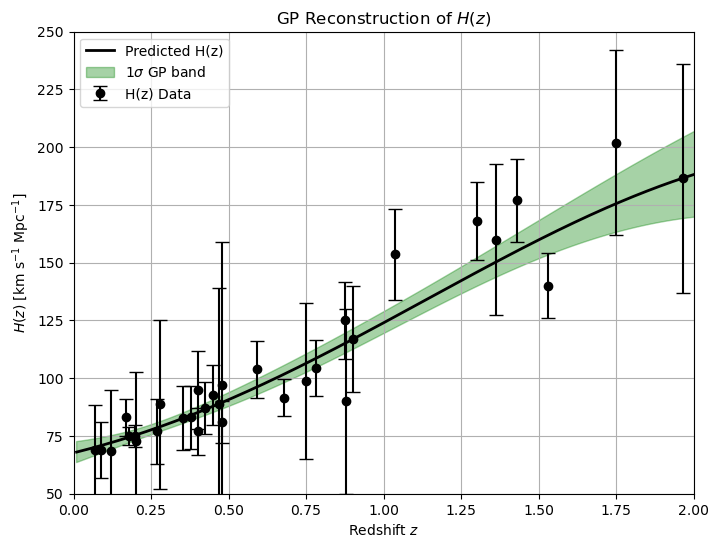

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

# Original H(z) data with error bars
plt.errorbar(
    z,
    H,
    yerr=Herr,
    fmt='o',
    color='k',
    capsize=5,
    label='H(z) Data'
)

# GP mean reconstruction
plt.plot(
    zrec,
    Hrec,
    'k-',
    linewidth=2,
    label='Predicted H(z)'
)

# 1σ confidence band
plt.fill_between(
    zrec,
    Hrec - errrec,
    Hrec + errrec,
    color='green',
    alpha=0.35,
    label=r'$1\sigma$ GP band'
)

plt.xlim(0,2)
plt.ylim(50,250)

plt.xlabel("Redshift $z$")
plt.ylabel(r"$H(z)$ [km s$^{-1}$ Mpc$^{-1}$]")
plt.title("GP Reconstruction of $H(z)$")

plt.grid(True)
plt.legend()

plt.show()

: 

: 